# Connecting Agents: One REST API with LangGraph

**Scenario:** A technical-support copilot checks a device's warranty using one authoritative mock REST endpoint.

**Learning objectives**
- Start a mock FastAPI service inside Jupyter (no external `.py` file).
- Wrap a single HTTP endpoint as a LangChain tool with timeouts and safe errors.
- Build a **LangGraph StateGraph** explicitly using nodes and edges.
- Inspect which nodes and tools executed.

**Architecture:** `START → agent → [tool needed?] → warranty_tool → agent → END`

The graph has two nodes (`agent`, `tools`) and one conditional edge. The only REST endpoint is `GET /warranty/{device_id}`.

In [ ]:
%pip install -q fastapi uvicorn requests python-dotenv langchain-openai langchain-core langgraph

In [1]:
import os
import requests
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition


load_dotenv(override=True)

model = os.getenv("OPENAI_MODEL", "qwen2.5:7b")

llm = ChatOpenAI(
    model=model,  #  "tencent/hy3:free",  "gpt-4.1-mini"
    base_url="http://localhost:11434/v1",  #"https://openrouter.ai/api/v1",
    api_key="olama",  # os.getenv("OPENROUTER_API_KEY"),
    temperature=0
)

## 1. single mock warranty endpoint

- Open a terminal in the project directory where you foud the `server.py`.

- Start the FastAPI server:`uvicorn server:app --reload --port 8000`
- If you are using uv: `uv run uvicorn server:app --reload --port 8000`

- Keep the server running in the background while executing the notebook. You can leave it running in a separate terminal or terminal tab.

- Open `http://127.0.0.1:8000/docs` to explore and test the API using Swagger UI.

## 2. Expose the endpoint as one tool

The tool returns a structured error for unknown devices; an unknown warranty is **not** the same as an expired warranty.

In [2]:
BASE = "http://127.0.0.1:8000"

@tool
def check_warranty(device_id: str) -> dict:
    """
    Look up the official warranty for a device ID such as PRINTER-1001.

    Expose the endpoint as one tool:
    The tool returns a structured error for unknown devices; an unknown warranty
    is not the same as an expired warranty.
    """
    try:
        response = requests.get(
            f"{BASE}/warranty/{device_id}", timeout=5
        )
        if response.status_code == 404:
            return {"device_id": device_id, "error": "unknown_device"}
        response.raise_for_status()
        return response.json()
    except requests.RequestException as exc:
        return {"device_id": device_id, "error": "api_unavailable",
                "detail": type(exc).__name__}

print(check_warranty.invoke({"device_id": "PRINTER-2001"}))
print(check_warranty.invoke({"device_id": "UNKNOWN-9999"}))


{'device_id': 'PRINTER-2001', 'expires': '2024-06-15', 'covered': False, 'checked_on': '2026-10-31'}
{'device_id': 'UNKNOWN-9999', 'error': 'unknown_device'}


## 3. Build the LangGraph from scratch

We explicitly add **nodes and edges** rather than using a prebuilt agent:
- `agent` asks the model whether it needs warranty data.
- `tools` executes `check_warranty` if requested.
- `tools_condition` routes to `tools` or `END`.
- The edge from `tools` back to `agent` lets the model incorporate the tool result.

A greeting can finish without calling the API.

In [3]:
model_with_tools = llm.bind_tools([check_warranty])

SYSTEM_PROMPT = (
    "You are a technical support assistant. "
    "For any question about a device's warranty, call check_warranty. "
    "Do not guess coverage, expiry dates, or warranty status. "
    "If a device is unknown or the API fails, explain that its status "
    "cannot be verified. Do not approve replacements."
)

def agent_node(state: MessagesState):
    reply = model_with_tools.invoke(
        [SystemMessage(content=SYSTEM_PROMPT), *state["messages"]]
    )
    return {"messages": [reply]}

# RESET: a fresh graph builder with exactly two nodes.
builder = StateGraph(MessagesState)
builder.add_node("agent", agent_node)
builder.add_node("tools", ToolNode([check_warranty]))

# EDGES
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)
builder.add_edge("tools", "agent")

graph = builder.compile()
print(graph.get_graph().draw_ascii())


        +-----------+         
        | __start__ |         
        +-----------+         
               *              
               *              
               *              
          +-------+           
          | agent |           
          +-------+*          
          .         *         
        ..           **       
       .               *      
+---------+         +-------+ 
| __end__ |         | tools | 
+---------+         +-------+ 


## 4. Run the graph and inspect its execution

In [4]:
questions = [
    "Hello!",
    "Is PRINTER-1001 under warranty?",
    "Check the warranty of PRINTER-2001.",
    "Is UNKNOWN-9999 covered?",
]

for question in questions:
    result = graph.invoke(
        {"messages": [HumanMessage(content=question)]}, config={"recursion_limit": 8})

    tools_used = [msg.name for msg in result["messages"] if msg.type == "tool"]
    print(f"\nQUESTION: {question}")
    print("TOOLS:", tools_used or "none")
    print("ANSWER:", result["messages"][-1].content)



QUESTION: Hello!
TOOLS: none
ANSWER: Hello! How can I assist you today? If you need to check the warranty status of a device, please provide me with the device ID.

QUESTION: Is PRINTER-1001 under warranty?
TOOLS: ['check_warranty']
ANSWER: The printer PRINTER-1001 is currently under warranty and will remain covered until December 31, 2028.

QUESTION: Check the warranty of PRINTER-2001.
TOOLS: ['check_warranty']
ANSWER: The warranty for PRINTER-2001 has expired as of June 15, 2024. It is not currently covered under warranty.

QUESTION: Is UNKNOWN-9999 covered?
TOOLS: ['check_warranty']
ANSWER: The status of UNKNOWN-9999 cannot be verified as it is an unknown device.


## 5. visualize the nodes and edges

Requires Graphviz for Mermaid PNG rendering in some environments; the ASCII graph above works without it.

In [7]:
from IPython.display import display, Markdown

mermaid_code = graph.get_graph().draw_mermaid()
markdown_diagram = f"```mermaid\n{mermaid_code}\n```"

display(Markdown(markdown_diagram))


```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools<hr/><small><em>__tools = check_warranty</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> tools;
	tools --> agent;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

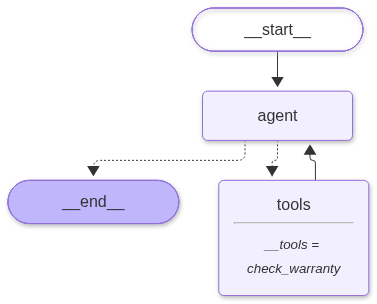

In [8]:
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

try:
    img_bytes = graph.get_graph().draw_mermaid_png(
        draw_method=MermaidDrawMethod.API
    )
    display(Image(img_bytes))
except Exception as exc:
    print("PNG rendering unavailable:", exc)


## Exercise

1. Ask the graph about `SCANNER-3001` and confirm it uses the warranty tool.
2. Ask about an unknown device and confirm the assistant does **not** say its warranty is expired.
3. Add another device to `WARRANTIES` and re-run the query.

### Suggested solution

In [7]:
exercise = graph.invoke(
    {"messages": [HumanMessage(content="Is SCANNER-3001 covered?")]},
    config={"recursion_limit": 8},
)
print("Tools:", [m.name for m in exercise["messages"] if m.type == "tool"])
print("Answer:", exercise["messages"][-1].content)

# To add a device, update the mock database in the running notebook:
# WARRANTIES["PRINTER-4001"] = "2029-01-01"


Tools: ['check_warranty']
Answer: Yes, the device SCANNER-3001 is currently covered under warranty. The warranty expires on September 30, 2027.
